# 01 · Exploratory Data Analysis

**Project goal:** given a user's history of game reviews, recommend 10 games they're likely to play and recommend next.

**Data:** Kaggle *Game Recommendations on Steam* (antonkozyriev), converted to parquet by `src/convert_parquet.py`.

| Table | One row = |
|---|---|
| `recommendations` | one user's review of one game (thumbs up/down, hours played, date) |
| `games` | one game: title, release date, platforms, price, rating |
| `games_metadata` | one game: description and user tags |
| `users` | one user: products owned and reviews written |

**This notebook answers:**
1. How big is the data and what period does it cover?
2. Is it clean (row counts, nulls, duplicates, odd values)?
3. How are reviews spread across games and users?
4. How representative are reviewers of Steam users?
5. How well does the dataset cover Steam's catalogue, and how much DLC is in it?

The findings and the cleaning decisions they led to are summarised at the end.

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
DATA = ROOT / "data" / "processed"

# recommendations has 41M rows -> keep it lazy (scan) and only collect results.
# The other tables are small enough to load fully.
recs = pl.scan_parquet(DATA / "recommendations.parquet")
games = pl.read_parquet(DATA / "games.parquet")
meta = pl.read_parquet(DATA / "games_metadata.parquet")
users = pl.read_parquet(DATA / "users.parquet")

pl.Config.set_tbl_cols(12)
plt.rcParams["figure.figsize"] = (9, 4)

## 2. The tables

In [2]:
for name, df in [("games", games), ("games_metadata", meta), ("users", users)]:
    print(f"{name:16s} {df.height:>12,} rows  {df.width} columns")
print(f"{'recommendations':16s} {recs.select(pl.len()).collect().item():>12,} rows")

recs.collect_schema()

games                  50,872 rows  13 columns
games_metadata         50,872 rows  3 columns
users              14,306,064 rows  3 columns
recommendations    41,154,794 rows


Schema([('app_id', Int32),
        ('helpful', Int64),
        ('funny', Int64),
        ('date', Date),
        ('is_recommended', Boolean),
        ('hours', Float32),
        ('user_id', Int32),
        ('review_id', Int64)])

In [3]:
recs.head(5).collect()

app_id,helpful,funny,date,is_recommended,hours,user_id,review_id
i32,i64,i64,date,bool,f32,i32,i64
975370,0,0,2022-12-12,true,36.299999,51580,0
304390,4,0,2017-02-17,false,11.5,2586,1
1085660,2,0,2019-11-17,true,336.5,253880,2
703080,0,0,2022-09-23,true,27.4,259432,3
526870,0,0,2021-01-10,true,7.9,23869,4


## 3. Overview of `recommendations`
Mean vs median hours shows whether a few very long playtimes pull the average up.

In [4]:
overview = recs.select(
    pl.len().alias("reviews"),
    pl.col("user_id").n_unique().alias("users"),
    pl.col("app_id").n_unique().alias("games"),
    pl.col("date").min().alias("first_review"),
    pl.col("date").max().alias("last_review"),
    pl.col("is_recommended").mean().alias("share_recommended"),
    pl.col("hours").mean().alias("avg_hours"),
    pl.col("hours").median().alias("median_hours"),
).collect()

overview

reviews,users,games,first_review,last_review,share_recommended,avg_hours,median_hours
u32,u32,u32,date,date,f64,f32,f32
41154794,13781059,37610,2010-10-15,2022-12-31,0.857844,100.602242,27.299999


## 4. Data quality

### 4.1 Row count: CSV vs parquet
Confirms the parquet conversion didn't drop or duplicate any rows.

In [5]:
csv_rows = pl.scan_csv(RAW / "recommendations.csv").select(pl.len()).collect().item()
parquet_rows = recs.select(pl.len()).collect().item()

assert csv_rows == parquet_rows, f"Mismatch: CSV {csv_rows:,} vs parquet {parquet_rows:,}"
print(f"Row counts match: {parquet_rows:,}")

Row counts match: 41,154,794


### 4.2 Missing values

In [6]:
recs.null_count().collect()

app_id,helpful,funny,date,is_recommended,hours,user_id,review_id
u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0


### 4.3 Duplicate (user_id, app_id) pairs
A user can review each game only once, so any pair appearing twice is a duplicate.

In [7]:
dupe_pairs = (
    recs.group_by(["user_id", "app_id"])
    .len()
    .filter(pl.col("len") > 1)
    .collect(engine="streaming")
)
print(f"Duplicate pairs: {dupe_pairs.height:,}  (extra rows: {(dupe_pairs['len'] - 1).sum():,})")

# Look at the duplicated rows themselves
dupe_rows = (
    recs.join(dupe_pairs.lazy().select("user_id", "app_id"), on=["user_id", "app_id"])
    .sort("user_id", "app_id", "date")
    .collect(engine="streaming")
)
print("Date range of duplicates:", dupe_rows["date"].min(), "to", dupe_rows["date"].max())
dupe_rows.head(6)

Duplicate pairs: 21  (extra rows: 21)


Date range of duplicates: 2014-09-26 to 2022-07-10


app_id,helpful,funny,date,is_recommended,hours,user_id,review_id
i32,i64,i64,date,bool,f32,i32,i64
1205960,0,0,2021-12-03,true,3.0,1085990,38113748
1205960,0,0,2021-12-04,false,3.0,1085990,36533636
440,0,0,2021-12-02,true,658.0,2433696,24170089
440,0,0,2021-12-04,true,658.0,2433696,24887439
1454400,0,0,2021-12-03,true,21.4,3054178,23765890
1454400,0,0,2021-12-07,true,21.4,3054178,15321463


### 4.4 Hours played
`hours` range, and reviews written with 0 hours played.

In [8]:
recs.select(
    pl.col("hours").min().alias("min_hours"),
    pl.col("hours").max().alias("max_hours"),
    (pl.col("hours") == 1000).sum().alias("rows_at_1000"),
    (pl.col("hours") == 0).sum().alias("zero_hours"),
    ((pl.col("hours") == 0) & pl.col("is_recommended")).sum().alias("zero_hours_recommended"),
    (pl.col("hours") == 0).mean().alias("share_zero_hours"),
).collect()

min_hours,max_hours,rows_at_1000,zero_hours,zero_hours_recommended,share_zero_hours
f32,f32,u32,u32,u32,f64
0.0,1000.0,26,176329,105703,0.004285


Which games get the most zero-hour thumbs up?

In [9]:
(
    recs.filter((pl.col("hours") == 0) & pl.col("is_recommended"))
    .group_by("app_id")
    .len()
    .sort("len", descending=True)
    .head(10)
    .collect()
    .join(games.select("app_id", "title", "price_final"), on="app_id", how="left")
)

app_id,len,title,price_final
i32,u32,str,f64
792220,2323,"""Paunch""",0.0
340,2202,"""Half-Life 2: Lost Coast""",0.0
1806840,1927,"""100 hidden frogs""",0.0
80,1375,"""Counter-Strike: Condition Zero""",9.99
353560,1288,"""Plug & Play""",2.99
34900,1147,"""Bad Rats: the Rats' Revenge""",0.99
744810,1016,"""A Raven Monologue""",0.0
223710,914,"""Cry of Fear""",0.0
353360,854,"""how do you Do It?""",0.0


## 5. Distributions

### 5.1 Hours played
Plotted on a log scale (`log1p` = log(1 + hours), so 0 hours stays at 0).

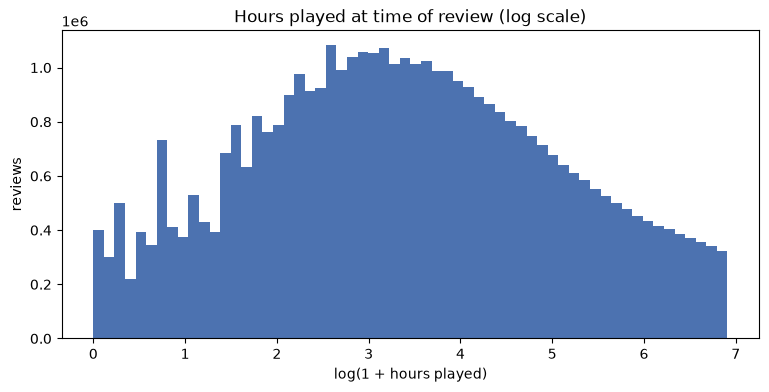

In [10]:
hours = recs.select(pl.col("hours").log1p()).collect()["hours"]

fig, ax = plt.subplots()
ax.hist(hours, bins=60, color="#4C72B0")
ax.set_xlabel("log(1 + hours played)")
ax.set_ylabel("reviews")
ax.set_title("Hours played at time of review (log scale)")
plt.show()

### 5.2 Reviews per game
How concentrated is attention on a few popular games? This matters because collaborative models can only learn games with enough reviews.

In [11]:
per_game = (
    recs.group_by("app_id")
    .len()
    .sort("len", descending=True)
    .collect(engine="streaming")
)
total = per_game["len"].sum()

pl.DataFrame({
    "top_n_games": [100, 1_000, 5_000, 10_000],
    "share_of_reviews": [per_game["len"][:n].sum() / total for n in [100, 1_000, 5_000, 10_000]],
})

top_n_games,share_of_reviews
i64,f64
100,0.291247
1000,0.743411
5000,0.93854
10000,0.975744


In [12]:
print("Games with <5 reviews: ", (per_game["len"] < 5).sum())
print("Games with <50 reviews:", (per_game["len"] < 50).sum())
per_game["len"].describe()

Games with <5 reviews:  2012
Games with <50 reviews: 20633


statistic,value
str,f64
"""count""",37610.0
"""null_count""",0.0
"""mean""",1094.251369
"""std""",7689.340463
"""min""",1.0
"""25%""",13.0
"""50%""",39.0
"""75%""",180.0
"""max""",319492.0


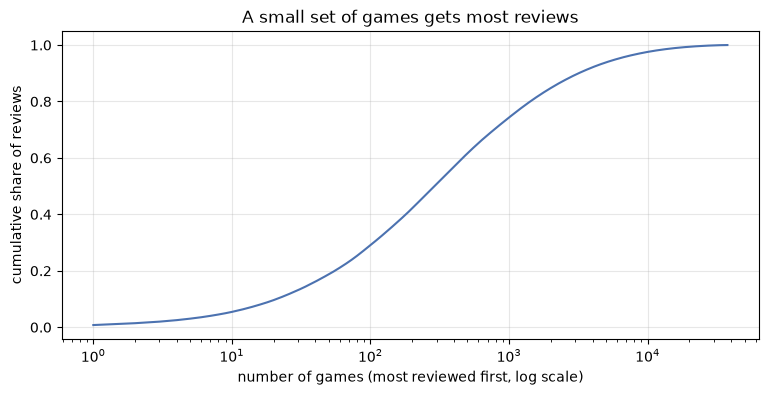

In [13]:
cum_share = per_game["len"].cum_sum() / total

fig, ax = plt.subplots()
ax.plot(range(1, len(cum_share) + 1), cum_share, color="#4C72B0")
ax.set_xscale("log")
ax.set_xlabel("number of games (most reviewed first, log scale)")
ax.set_ylabel("cumulative share of reviews")
ax.set_title("A small set of games gets most reviews")
ax.grid(alpha=0.3)
plt.show()

### 5.3 Reviews per user
How many users have enough history for a next-item recommender? The plan is to keep users with at least 5 interactions.

In [14]:
per_user = recs.group_by("user_id").len().collect(engine="streaming")

per_user.select(
    pl.len().alias("users"),
    (pl.col("len") == 1).mean().alias("share_1_review"),
    (pl.col("len") >= 5).mean().alias("share_5plus"),
    (pl.col("len") >= 5).sum().alias("users_5plus"),
    pl.col("len").median().alias("median_reviews"),
    pl.col("len").max().alias("max_reviews"),
)

users,share_1_review,share_5plus,users_5plus,median_reviews,max_reviews
u32,f64,f64,u32,f64,u32
13781059,0.549524,0.138656,1910831,1.0,6045


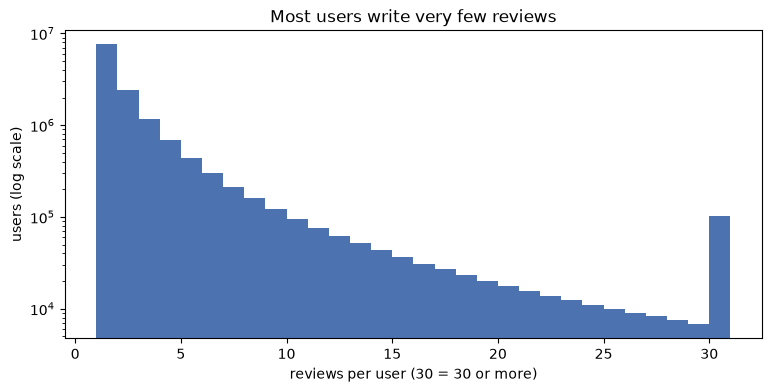

In [15]:
counts = per_user["len"].clip(upper_bound=30)

fig, ax = plt.subplots()
ax.hist(counts, bins=range(1, 32), color="#4C72B0")
ax.set_yscale("log")
ax.set_xlabel("reviews per user (30 = 30 or more)")
ax.set_ylabel("users (log scale)")
ax.set_title("Most users write very few reviews")
plt.show()

## 6. The `users` table

### 6.1 Extremes
Users with the most reviews and the most products.

In [16]:
users.sort("reviews", descending=True).head(10)

user_id,products,reviews
i64,i64,i64
11764552,7898,6045
5112758,1226,4152
11656130,1807,3840
5669734,4737,3479
11553593,1919,3392
5390510,721,3023
4457971,2043,2720
4318160,3702,2714
574944,5920,2626


In [17]:
users.select(
    pl.len().alias("users"),
    (pl.col("reviews") == 0).sum().alias("zero_reviews"),
    (pl.col("products") == 0).sum().alias("zero_products"),
    pl.col("products").median().alias("median_products"),
    pl.col("reviews").median().alias("median_reviews"),
)

users,zero_reviews,zero_products,median_products,median_reviews
u32,u32,u32,f64,f64
14306064,525005,139318,55.0,1.0


### 6.2 Does `users.reviews` match the rows in `recommendations`?
If not, `users.reviews` probably counts reviews outside this dataset (e.g. games that were dropped).

In [18]:
check = users.join(per_user, on="user_id", how="left").with_columns(
    pl.col("len").fill_null(0).alias("rows_in_recs")
)

check.select(
    (pl.col("reviews") == pl.col("rows_in_recs")).mean().alias("share_exact_match"),
    (pl.col("reviews") > pl.col("rows_in_recs")).mean().alias("share_more_in_users"),
    (pl.col("reviews") < pl.col("rows_in_recs")).mean().alias("share_fewer_in_users"),
    (pl.col("reviews") - pl.col("rows_in_recs")).median().alias("median_difference"),
)

share_exact_match,share_more_in_users,share_fewer_in_users,median_difference
f64,f64,f64,f64
1.0,0.0,0.0,0.0


### 6.3 Selection bias: what share of owned products get reviewed?
Our data only sees games a user chose to review. The lower this share, the more of each user's library is invisible to the model.

In [19]:
owners = users.filter(pl.col("products") > 0)

owners.select(
    (pl.col("reviews").sum() / pl.col("products").sum()).alias("overall_share_reviewed"),
    (pl.col("reviews") / pl.col("products")).median().alias("median_user_share_reviewed"),
)

overall_share_reviewed,median_user_share_reviewed
f64,f64
0.024641,0.030928


## 7. Catalogue coverage and DLC

### 7.1 How many listed games have reviews?

In [20]:
reviewed_ids = per_game.select("app_id").with_columns(pl.col("app_id").cast(pl.Int64))
games_cov = games.with_columns(pl.col("app_id").is_in(reviewed_ids["app_id"].implode()).alias("has_reviews"))

print(f"Games listed:          {games.height:,}")
print(f"Games with reviews:    {games_cov['has_reviews'].sum():,}")
print(f"Release dates:         {games['date_release'].min()} to {games['date_release'].max()}")
print(f"Released after 2022 (no reviews possible): {games.filter(pl.col('date_release') > pl.date(2022, 12, 31)).height:,}")

Games listed:          50,872
Games with reviews:    37,610
Release dates:         1997-06-30 to 2023-10-24
Released after 2022 (no reviews possible): 3,425


### 7.2 How much DLC is there?
`games` has no DLC/type column, so this uses two rough signals: a DLC-style title, or tags from `games_metadata`. The Steam API `type` field would give exact labels later.

In [21]:
dlc_pattern = r"(?i)\bDLC\b|soundtrack|\bOST\b|season pass|expansion pack|costume|skin pack"

dlc_check = (
    games.select("app_id", "title")
    .join(meta.select("app_id", "tags"), on="app_id", how="left")
    .join(per_game.with_columns(pl.col("app_id").cast(pl.Int64)), on="app_id", how="inner")
    .with_columns(
        pl.col("title").str.contains(dlc_pattern).alias("dlc_title"),
        pl.col("tags").list.contains("Soundtrack").fill_null(False).alias("tag_soundtrack"),
        (pl.col("tags").list.len().fill_null(0) == 0).alias("no_tags"),
        (pl.col("len").rank("ordinal", descending=True) <= 5_000).alias("in_top_5000"),
    )
)

dlc_check.group_by("in_top_5000").agg(
    pl.len().alias("games"),
    pl.col("dlc_title").sum(),
    pl.col("tag_soundtrack").sum(),
    pl.col("no_tags").sum(),
    pl.col("len").filter(pl.col("dlc_title")).sum().alias("reviews_on_dlc_title"),
).sort("in_top_5000", descending=True)

in_top_5000,games,dlc_title,tag_soundtrack,no_tags,reviews_on_dlc_title
bool,u32,u32,u32,u32,u32
true,5000,2,65,559,5232
false,32610,16,365,19,734


In [22]:
# The most-reviewed DLC-looking titles
dlc_check.filter(pl.col("dlc_title")).sort("len", descending=True).select("app_id", "title", "len").head(10)

app_id,title,len
i64,str,u32
230050,"""DLC Quest""",3444
115100,"""Costume Quest""",1788
275180,"""Costume Quest 2""",392
340320,"""Sinless + OST""",149
8660,"""GTR Evolution Expansion Pack f…",118
8690,"""STCC - The Game 1 - Expansion …",12
44670,"""WTCC 2010 – Expansion Pack for…",12
44650,"""GT Power Pack – Expansion Pack…",11
44660,"""RETRO – Expansion Pack for RAC…",10


## 8. Summary of findings

**Size and period**
- 41.15M reviews from 13.78M users on 37,610 games, written between Oct 2010 and **31 Dec 2022**.
- 85.8% of reviews are thumbs up, so "recommended" alone separates games weakly.

**Data quality**
- CSV and parquet row counts match; no missing values.
- 21 duplicate (user, game) pairs, all dated Dec 2021 with identical hours → a collection glitch.
- `hours` is capped at 1000 (26 rows sit exactly at the cap) and is right-skewed: mean 100.6 vs median 27.3. Use `log1p(hours)` if hours become a weight.
- 176k reviews have 0 hours; 105.7k of them are thumbs up, concentrated on free or meme games (Paunch, 100 hidden frogs, Bad Rats).

**Concentration**
- The top 1,000 games get 74% of reviews; the top 5,000 get 94%. Half of all games have fewer than 40 reviews.
- 55% of users wrote only one review; 1.91M users (13.9%) have 5 or more. The 5-interaction filter will remove most users but keep the users a next-item model can learn from.
- The heaviest reviewer wrote 6,045 reviews: test heavy-user weighting as an ablation, as planned.

**Representativeness (selection bias)**
- `users.reviews` matches the row counts in `recommendations` exactly, so the tables are consistent.
- Users review only ~2.5% of the products they own (median user: 3.1%). The model sees a small, self-selected slice of each library, so results apply to reviewers, not all Steam players.

**Catalogue coverage and DLC**
- 50,872 games are listed, but only 37,610 have reviews; 3,425 were released after the last review date.
- Almost no reviewed items look like DLC: only 18 DLC-style titles, and most of those are full games with "DLC", "Costume" or "Expansion" in the name. **The Steam API is not needed for DLC labels now.**
- 559 of the top 5,000 games have no tags in `games_metadata`, which matters for the later tag-based hybrid model.

**Cleaning decisions (applied in `src/prepare.py`)**
1. Zero-hour thumbs-up reviews do not count as a like.
2. Duplicates: keep the latest row per (user, game).
3. Then iteratively drop users and games with fewer than 5 interactions.

**Still open:** what counts as a like overall (thumbs up only / any review / hours-based), what to do with the 1000-hour cap, and how to treat heavy reviewers.